# Notebook 13 - EDA Report
Sprint 4 - EDA

# Telco Customer Churn: Exploratory Data Analysis Report
**How the report is built:** the facts in each section (counts, percentages, statistics) are calculated by the code cells, so they are taken from the real data when the notebook is run. The text around them explains what they mean. Nothing in this notebook cleans or changes the data. The cleaning is the job of the next sprint.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for the report only; the original data stays unchanged
d = df.copy()
d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
d["Churn_num"] = (d["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn"]]
n = len(d)

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    total = table.values.sum()
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / total
    chi2 = ((table.values - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (total * (min(table.shape) - 1)))

print("Report ready:", n, "rows")

Report ready: 7043 rows


# 1. Dataset Overview

| Item | Description |
|---|---|
| Dataset name | Telco Customer Churn (IBM sample dataset) |
| Source | Kaggle, file WA_Fn-UseC_-Telco-Customer-Churn.csv |
| Domain | Telecom, subscription based customer retention |
| One row represents | One customer |
| Target variable | Churn (Yes or No), so the task is binary classification |
| Identifier | customerID |
| Business question | Which customers are likely to leave, and what can be done to keep them? |

**Feature groups**

| Group | Columns |
|---|---|
| Customer profile | gender, SeniorCitizen, Partner, Dependents |
| Phone services | PhoneService, MultipleLines |
| Internet services | InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies |
| Account and billing | tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges |
| Identifier and target | customerID, Churn |

In [2]:
print("Rows:", n)
print("Columns:", df.shape[1])
print("Memory (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))
print()
print("Stored data types:")
print(df.dtypes.astype(str).value_counts().to_string())
print()
print("Numerical features (by meaning):", num_cols)
print("Categorical features:", len(cat_cols))
print("Date or time columns:", df.select_dtypes(include=["datetime"]).columns.tolist())
print()

counts = df["Churn"].value_counts()
print("Target distribution:")
print(pd.DataFrame({"count": counts, "percent": (counts / n * 100).round(1)}))

Rows: 7043
Columns: 21
Memory (MB): 1.86

Stored data types:
str        18
int64       2
float64     1

Numerical features (by meaning): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: 16
Date or time columns: []

Target distribution:
       count  percent
Churn                
No      5174     73.5
Yes     1869     26.5


**Summary:** The dataset has one row per customer with a mix of customer profile, service and billing information. Most columns are categorical with 2 to 4 categories, and three are numerical (tenure, MonthlyCharges, TotalCharges). There is no date column, and the target is binary with about one customer in four in the positive class.

# 2. Data Quality

The checks come from Notebook 3. Here they are repeated in one table, so the full picture is in one place.

In [3]:
text_cols = d.select_dtypes(exclude="number").columns

blank_total = 0
for col in text_cols:
    blank_total = blank_total + (d[col].astype(str).str.strip() == "").sum()

null_like = ["", " ", "na", "n/a", "nan", "null", "none", "unknown", "-", "?", "missing", "not available"]
null_like_total = 0
for col in text_cols:
    null_like_total = null_like_total + d[col].astype(str).str.strip().str.lower().isin(null_like).sum()

non_numeric_total = pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()
blank_rows = d[d["TotalCharges"].isna()]
cols_wo_id = [c for c in df.columns if c != "customerID"]

quality = pd.DataFrame([
    ["Missing values found by isnull", int(df.isnull().sum().sum())],
    ["Blank strings (hidden missing values)", int(blank_total)],
    ["Null-like words or symbols (including blanks)", int(null_like_total)],
    ["TotalCharges values that are not numbers", int(non_numeric_total)],
    ["... of which the customer has tenure 0", int((blank_rows["tenure"] == 0).sum())],
    ["Completely duplicated rows", int(df.duplicated().sum())],
    ["Duplicate customerID values", int(df["customerID"].duplicated().sum())],
    ["Extra rows identical in all columns except customerID", int(df.duplicated(subset=cols_wo_id).sum())],
    ["Negative values in numerical columns", int((d[num_cols] < 0).sum().sum())],
    ["Columns stored with the wrong type", 2],
], columns=["check", "result"])
quality

,check,result
0,Missing values found by isnull,0
1,Blank strings (hidden missing values),0
2,Null-like words or symbols (including blanks),0
3,TotalCharges values that are not numbers,11
4,... of which the customer has tenure 0,11
5,Completely duplicated rows,0
6,Duplicate customerID values,0
7,Extra rows identical in all columns except customerID,22
8,Negative values in numerical columns,0
9,Columns stored with the wrong type,2


**Summary of data quality**

- The data is mostly clean. There are no missing values in the usual sense, no complete duplicates, no duplicate ids, no negative values and no spelling problems in the categories.
- There is one hidden missing value problem: TotalCharges contains blank spaces for customers with tenure 0. These are new customers who have not yet been billed. This is why pandas reads the column as text.
- Two columns have the wrong stored type: TotalCharges (text, should be numeric) and SeniorCitizen (number, should be categorical).
- Some rows are identical in everything except the customer id. They may be different customers with the same plan, so they are potential duplicates that need a review, and not rows to delete automatically.
- Seven columns use a third label (No internet service or No phone service) next to Yes and No. These are valid values, but they need a decision during encoding.

# 3. Statistical Findings

In [4]:
rows = []
for col in num_cols:
    s = d[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    rows.append([col, round(s.mean(), 1), round(s.median(), 1), round(s.std(), 1), round(iqr, 1),
                 round(s.std() / s.mean(), 2), round(s.min(), 1), round(s.max(), 1),
                 round(s.skew(), 2), round(s.kurt(), 2),
                 int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()), int((z.abs() > 3).sum())])

stats = pd.DataFrame(rows, columns=["feature", "mean", "median", "std", "IQR", "coef_variation", "min", "max",
                                    "skewness", "kurtosis", "outliers_IQR", "outliers_Z3"])
stats

,feature,mean,median,std,IQR,coef_variation,min,max,skewness,kurtosis,outliers_IQR,outliers_Z3
0,tenure,32.4,29.0,24.6,46.0,0.76,0.0,72.0,0.24,-1.39,0,0
1,MonthlyCharges,64.8,70.4,30.1,54.4,0.46,18.2,118.8,-0.22,-1.26,0,0
2,TotalCharges,2283.3,1397.5,2266.8,3393.3,0.99,18.8,8684.8,0.96,-0.23,0,0


**Central tendency:** For tenure and MonthlyCharges the mean and the median are close, but few customers are near the center, because both variables have more than one peak. For TotalCharges the mean is far above the median.

**Dispersion:** The three features are on very different scales (tenure up to 72, MonthlyCharges up to about 119, TotalCharges up to several thousand). TotalCharges has the biggest relative spread.

**Distribution:** None of the numerical features is normal. Tenure is U shaped with spikes at the first and the last month. MonthlyCharges has a large peak at the low end (customers without internet) and a broad group at the high end. TotalCharges is right skewed. A low skewness for tenure and MonthlyCharges does not mean they are normal, since the very negative kurtosis shows that they are flat or multimodal.

**Outliers:** The IQR method and the Z-score method find no univariate outliers. A small number of customers are unusual in the combination of tenure, MonthlyCharges and TotalCharges, but they look like plan changes and not errors. The long tail of TotalCharges is natural, because long term customers with high bills accumulate large totals.

In [5]:
# categorical summary
rows = []
for col in cat_cols:
    vc = d[col].value_counts()
    rows.append([col, len(vc), vc.index[0], round(vc.iloc[0] / n * 100, 1), vc.index[-1], round(vc.iloc[-1] / n * 100, 1)])

cat_summary = pd.DataFrame(rows, columns=["feature", "categories", "largest", "largest_%", "smallest", "smallest_%"])
cat_summary.sort_values("largest_%", ascending=False)

,feature,categories,largest,largest_%,smallest,smallest_%
4,PhoneService,2,Yes,90.3,No,9.7
1,SeniorCitizen,2,0,83.8,1,16.2
3,Dependents,2,No,70.0,Yes,30.0
14,PaperlessBilling,2,Yes,59.2,No,40.8
13,Contract,3,Month-to-month,55.0,One year,20.9
2,Partner,2,No,51.7,Yes,48.3
0,gender,2,Male,50.5,Female,49.5
7,OnlineSecurity,3,No,49.7,No internet service,21.7
10,TechSupport,3,No,49.3,No internet service,21.7
5,MultipleLines,3,No,48.1,No phone service,9.7


**Categorical features:** All categorical features have low cardinality (2 to 4 categories) and no rare category (the smallest group has several hundred customers). Gender is evenly split. PhoneService and SeniorCitizen are dominated by one label. The target is imbalanced, with the minority class (Churn = Yes) at roughly a quarter of the data.

# 4. Relationship Findings

In [6]:
print("Correlation matrix of numerical features and the target:")
print(d[num_cols + ["Churn_num"]].corr().round(2))
print()

assoc = pd.Series({col: cramers_v(d[col], d["Churn"]) for col in cat_cols}).sort_values(ascending=False)
print("Association of categorical features with Churn (Cramers V):")
print(assoc.round(3).to_string())

Correlation matrix of numerical features and the target:
                tenure  MonthlyCharges  TotalCharges  Churn_num
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_num        -0.35            0.19         -0.20       1.00

Association of categorical features with Churn (Cramers V):
Contract            0.410
OnlineSecurity      0.347
TechSupport         0.343
InternetService     0.322
PaymentMethod       0.303
OnlineBackup        0.292
DeviceProtection    0.282
StreamingMovies     0.231
StreamingTV         0.231
PaperlessBilling    0.192
Dependents          0.164
SeniorCitizen       0.151
Partner             0.150
MultipleLines       0.040
PhoneService        0.012
gender              0.009


In [7]:
# churn rate in the most important groups
tables = {}
tables["Contract"] = d.groupby("Contract")["Churn_num"].mean() * 100
tables["InternetService"] = d.groupby("InternetService")["Churn_num"].mean() * 100
tables["PaymentMethod"] = d.groupby("PaymentMethod")["Churn_num"].mean() * 100
tables["TechSupport"] = d.groupby("TechSupport")["Churn_num"].mean() * 100
tables["SeniorCitizen"] = d.groupby("SeniorCitizen")["Churn_num"].mean() * 100

for name, t in tables.items():
    print(name)
    print(t.round(1).to_string())
    print()

Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

InternetService
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4

PaymentMethod
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1

TechSupport
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2

SeniorCitizen
SeniorCitizen
0    23.6
1    41.7



**Correlations**
- Strong: tenure and TotalCharges, because the total is built from tenure and the monthly price.
- Moderate: MonthlyCharges and TotalCharges.
- Weak: tenure and MonthlyCharges.
- Negative with churn: tenure (longer tenure, less churn). MonthlyCharges has a weak positive relation with churn.
- Among the encoded categorical columns, the No internet service columns are perfectly correlated with each other, which is a result of the one-hot encoding of repeated labels.

**Feature relationships**
- Contract is the strongest categorical feature for churn, followed by online security, tech support, internet service and payment method. Gender and PhoneService are almost unrelated to churn.
- Contract and internet service interact. Fiber optic customers on month-to-month contracts have the highest churn rate, and the fiber effect is much smaller on long contracts.
- The monthly price is explained mostly by the service type, and not by tenure.
- Churn falls as tenure rises, inside every contract type.

**Important patterns**
- Churn is concentrated in the first year of the customer life.
- Month-to-month customers produce most of the churners.
- Customers with more protective services churn less. This is an association, not a proven cause.
- Electronic check users churn more, partly because they are more often on month-to-month contracts.

# 5. Visualization Findings

One figure with six panels summarizes the most important visual insights of the sprint.

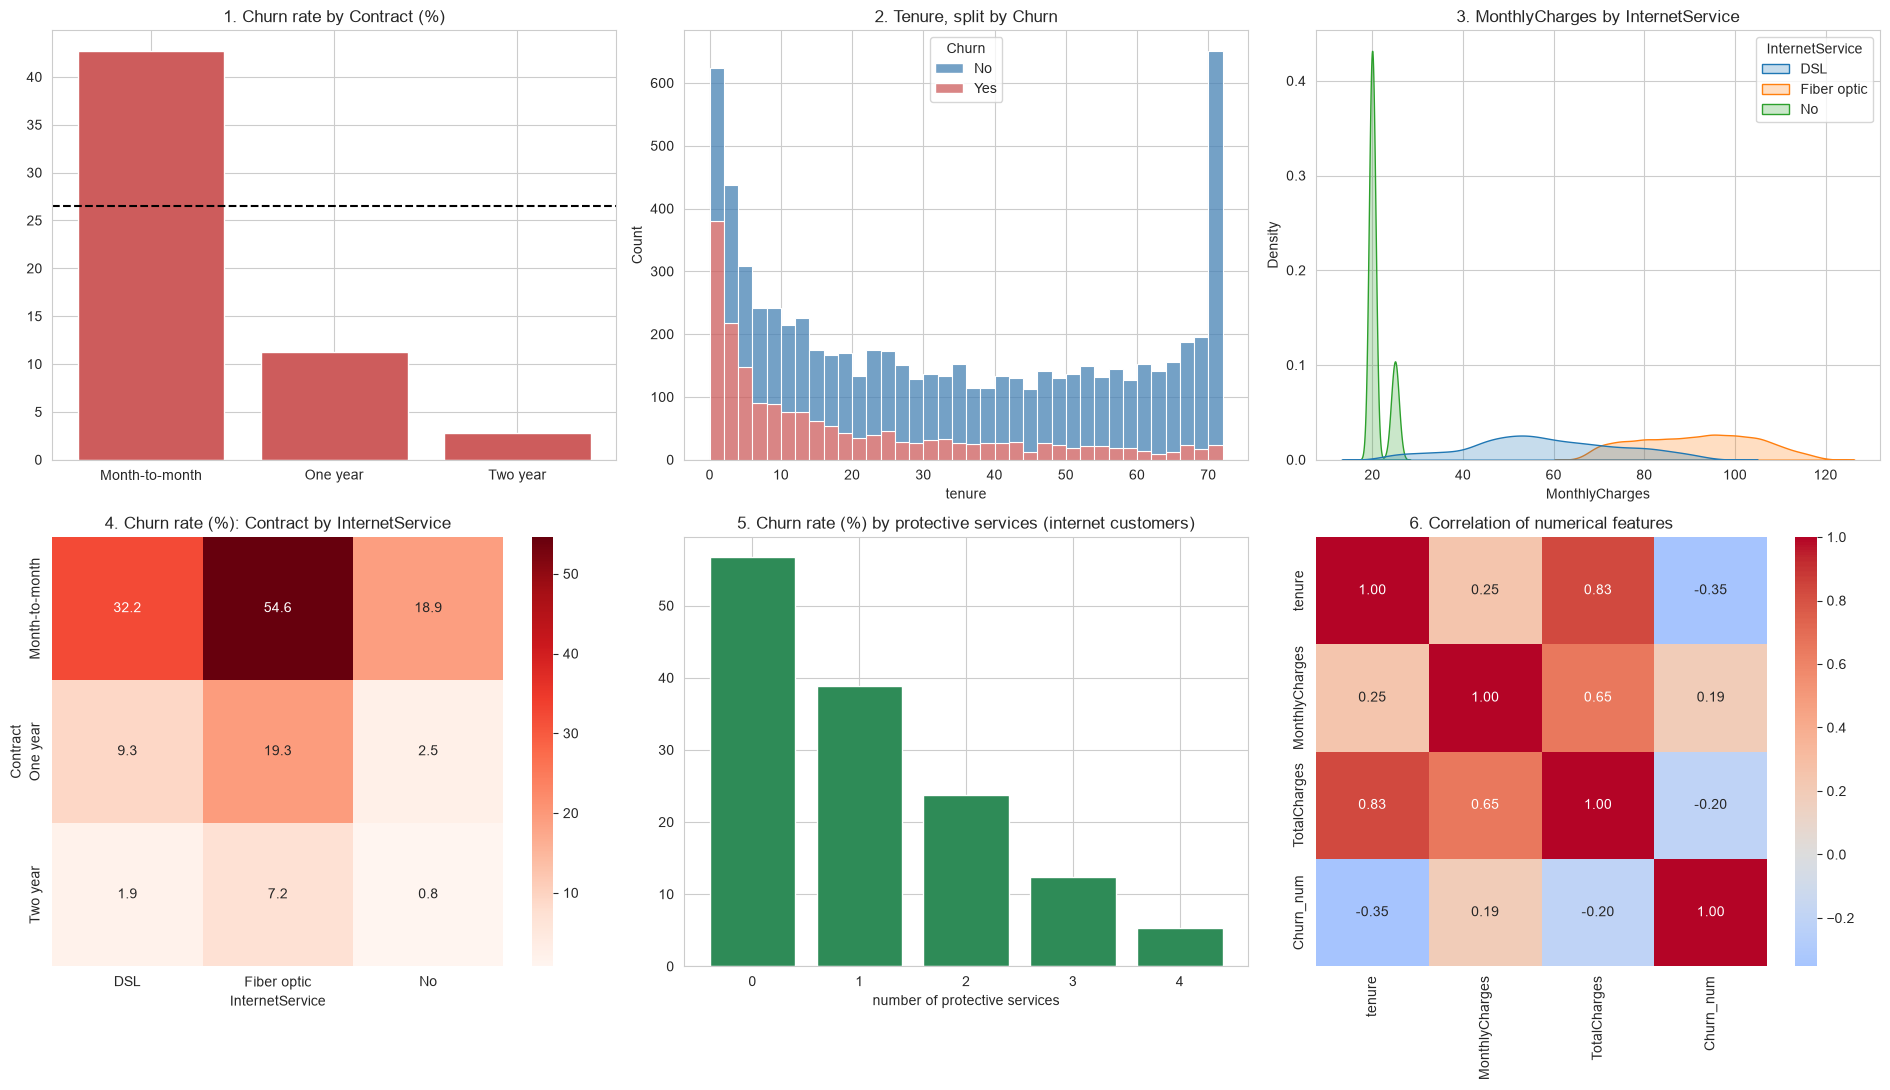

In [8]:
contract_order = ["Month-to-month", "One year", "Two year"]
protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
d["n_protect"] = (d[protect] == "Yes").sum(axis=1)
internet = d[d["InternetService"] != "No"]

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# 1 contract
rate = d.groupby("Contract")["Churn_num"].mean().reindex(contract_order) * 100
axes[0, 0].bar(rate.index, rate.values, color="indianred")
axes[0, 0].axhline(d["Churn_num"].mean() * 100, color="black", linestyle="--")
axes[0, 0].set_title("1. Churn rate by Contract (%)")

# 2 tenure histogram
sns.histplot(data=d, x="tenure", hue="Churn", bins=36, multiple="stack",
             palette={"No": "steelblue", "Yes": "indianred"}, ax=axes[0, 1])
axes[0, 1].set_title("2. Tenure, split by Churn")

# 3 monthly charges by internet service
sns.kdeplot(data=d, x="MonthlyCharges", hue="InternetService", fill=True, common_norm=False, ax=axes[0, 2])
axes[0, 2].set_title("3. MonthlyCharges by InternetService")

# 4 contract by internet heatmap
pivot = d.pivot_table(index="Contract", columns="InternetService", values="Churn_num", aggfunc="mean").reindex(contract_order) * 100
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=axes[1, 0])
axes[1, 0].set_title("4. Churn rate (%): Contract by InternetService")

# 5 protective services
prot = internet.groupby("n_protect")["Churn_num"].mean() * 100
axes[1, 1].bar(prot.index.astype(str), prot.values, color="seagreen")
axes[1, 1].set_xlabel("number of protective services")
axes[1, 1].set_title("5. Churn rate (%) by protective services (internet customers)")

# 6 correlation heatmap
sns.heatmap(d[num_cols + ["Churn_num"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 2])
axes[1, 2].set_title("6. Correlation of numerical features")

plt.tight_layout()
plt.show()

**Reading the figure**

1. Contract: the churn rate drops sharply from month-to-month to one year to two year contracts.
2. Tenure: the red part (churners) is concentrated in the first months, and the longest customers almost never churn.
3. MonthlyCharges: the monthly price forms groups that follow the internet service type, which explains why the distribution has several peaks.
4. Contract by InternetService: the highest risk cell is month-to-month with fiber optic, and long contracts have low rates for every service.
5. Protective services: churn falls as the number of protective services grows.
6. Correlations: tenure and TotalCharges move together strongly, and tenure has the strongest negative relation with churn.

# 6. Potential Data Problems

This register lists the issues that must be handled in the preprocessing sprint. The evidence column is calculated from the data. No issue is fixed here.

In [9]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
same_as_no_internet = all((d[c] == "No internet service").equals(d["InternetService"] == "No") for c in addons)
third_label_cols = [c for c in cat_cols if d[c].isin(["No internet service", "No phone service"]).any()]
corr_tt = d["tenure"].corr(d["TotalCharges"])
skew_tc = d["TotalCharges"].skew()
minority = d["Churn_num"].mean() * 100
v_gender = assoc["gender"]
v_phone = assoc["PhoneService"]
tenure_counts = d["tenure"].value_counts()

problems = pd.DataFrame([
    ["High", "TotalCharges has the wrong data type", "TotalCharges",
     "Stored as " + str(df["TotalCharges"].dtype) + "; " + str(int(non_numeric_total)) + " values are not numbers",
     "Cannot be used as a number; breaks scaling and models",
     "Convert to numeric"],
    ["High", "Hidden missing values", "TotalCharges",
     str(int(non_numeric_total)) + " blank values, all with tenure 0: " + str(bool((blank_rows["tenure"] == 0).all())),
     "Model training fails or ignores these rows",
     "Decide: set to 0 (new customers, not yet billed) or drop the rows; document the choice"],
    ["Medium", "SeniorCitizen stored as a number", "SeniorCitizen",
     "Values: " + str(sorted(d["SeniorCitizen"].unique().tolist())),
     "Could be scaled as if it were a quantity",
     "Treat as a binary categorical feature"],
    ["Medium", "Third label in categorical features", ", ".join(third_label_cols),
     str(len(third_label_cols)) + " columns; No internet service is identical to InternetService = No in all add-on columns: " + str(same_as_no_internet),
     "Creates perfectly redundant columns; merging blindly hides a very low risk group",
     "Test keeping three labels against merging; drop one dummy per feature for linear models"],
    ["Medium", "Target class imbalance", "Churn",
     "Minority class is " + str(round(minority, 1)) + " percent of the data",
     "Accuracy is misleading; the model may favor the majority class",
     "Stratified split; use precision, recall, F1 and ROC AUC; test class weights"],
    ["Medium", "Multicollinearity", "tenure, MonthlyCharges, TotalCharges",
     "Correlation between tenure and TotalCharges: " + str(round(corr_tt, 2)),
     "Unstable coefficients in linear models",
     "Drop or replace TotalCharges, or use a tree based model"],
    ["Medium", "Skewed feature", "TotalCharges",
     "Skewness: " + str(round(skew_tc, 2)),
     "Hurts models that assume symmetry",
     "Test a square root or log transformation"],
    ["Medium", "Very different feature scales", ", ".join(num_cols),
     "Maximums: " + ", ".join(str(round(d[c].max())) for c in num_cols),
     "Distance and gradient based models are dominated by the large scale",
     "Scale numerical features (fit on the training data only)"],
    ["Low", "Identifier column", "customerID",
     "Unique values: " + str(df["customerID"].nunique()) + " of " + str(n),
     "Would be memorized or create thousands of columns",
     "Drop before training"],
    ["Low", "Potential duplicate rows", "all except customerID",
     str(int(df.duplicated(subset=cols_wo_id).sum())) + " extra rows identical except for the id",
     "May count some customers twice, or may be genuine different customers",
     "Review before removing; do not delete automatically"],
    ["Low", "Spikes in tenure", "tenure",
     "Customers at 1 month: " + str(int(tenure_counts[1])) + "; at 72 months: " + str(int(tenure_counts[72])),
     "72 months is probably the limit of the observation window",
     "Document as a limitation; consider tenure bands"],
    ["Low", "Weak features", "gender, PhoneService",
     "Cramers V with churn: gender " + str(round(v_gender, 3)) + ", PhoneService " + str(round(v_phone, 3)),
     "Add noise and columns without information",
     "Test removal during feature selection"],
    ["Low", "Sensitive attributes", "gender, SeniorCitizen",
     "Present in the data",
     "May cause unfair treatment of customers",
     "Decide whether to use them; run a fairness check"],
], columns=["priority", "issue", "columns", "evidence", "impact_on_ML", "recommended_action"])

problems

,priority,issue,columns,evidence,impact_on_ML,recommended_action
0,High,TotalCharges has the wrong data type,TotalCharges,Stored as str; 11 values are not numbers,Cannot be used as a number; breaks scaling and models,Convert to numeric
1,High,Hidden missing values,TotalCharges,"11 blank values, all with tenure 0: True",Model training fails or ignores these rows,"Decide: set to 0 (new customers, not yet billed) or drop the rows; document the choice"
2,Medium,SeniorCitizen stored as a number,SeniorCitizen,"Values: [0, 1]",Could be scaled as if it were a quantity,Treat as a binary categorical feature
3,Medium,Third label in categorical features,"MultipleLines, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",7 columns; No internet service is identical to InternetService = No in all add-on columns: True,Creates perfectly redundant columns; merging blindly hides a very low risk group,Test keeping three labels against merging; drop one dummy per feature for linear models
4,Medium,Target class imbalance,Churn,Minority class is 26.5 percent of the data,Accuracy is misleading; the model may favor the majority class,"Stratified split; use precision, recall, F1 and ROC AUC; test class weights"
5,Medium,Multicollinearity,"tenure, MonthlyCharges, TotalCharges",Correlation between tenure and TotalCharges: 0.83,Unstable coefficients in linear models,"Drop or replace TotalCharges, or use a tree based model"
6,Medium,Skewed feature,TotalCharges,Skewness: 0.96,Hurts models that assume symmetry,Test a square root or log transformation
7,Medium,Very different feature scales,"tenure, MonthlyCharges, TotalCharges","Maximums: 72, 119, 8685",Distance and gradient based models are dominated by the large scale,Scale numerical features (fit on the training data only)
8,Low,Identifier column,customerID,Unique values: 7043 of 7043,Would be memorized or create thousands of columns,Drop before training
9,Low,Potential duplicate rows,all except customerID,22 extra rows identical except for the id,"May count some customers twice, or may be genuine different customers",Review before removing; do not delete automatically


# 7. Recommendations for the Next Sprint

These are suggestions to be tested in the preprocessing sprint. This sprint only identified the problems.

| Area | Columns | Suggested approach | Reason |
|---|---|---|---|
| Data type correction | TotalCharges, SeniorCitizen | Convert TotalCharges to numeric; treat SeniorCitizen as a category | The stored types do not match the meaning |
| Missing value treatment | TotalCharges (blank values) | Set to 0 for tenure 0 customers, or drop those rows; compare both | The blanks have a business reason (not yet billed), so a mean or median fill is not logical |
| Duplicates | Rows identical except for the id | Review, and keep unless there is another sign of duplication | They may be different customers |
| Outlier treatment | tenure, MonthlyCharges, TotalCharges | No row removal | No univariate outliers; flagged multivariate points look like valid plan changes |
| Encoding | Binary columns | Convert to 0 and 1 | Simple and lossless |
| Encoding | Contract | Compare ordinal encoding with one-hot | Contract has a natural order |
| Encoding | PaymentMethod, InternetService | One-hot encoding | Nominal with 3 to 4 categories |
| Encoding | Add-on columns with a third label | Compare keeping three labels with merging into No | The No internet service group behaves very differently from No |
| Scaling | Numerical features | Standardize for linear, KNN, SVM and neural models; skip for tree models | Features are on very different scales; fit the scaler on training data only |
| Feature transformation | TotalCharges | Test square root or log | It is right skewed |
| Feature engineering | tenure | Tenure bands (for example 0-12, 13-24, 25-48, 49-72) | Churn falls quickly and non-linearly with tenure |
| Feature engineering | Add-on columns | Number of protective services; number of all services | Combines overlapping columns into one useful signal |
| Feature engineering | Contract and InternetService | Interaction feature | The fiber effect depends on the contract |
| Feature engineering | PaymentMethod | Automatic payment indicator | Separates automatic from manual payment |
| Feature selection | gender, PhoneService, TotalCharges | Test removal | Weak signal, or redundant with other features |
| Data splitting | Whole dataset | Stratified train and test split and stratified cross validation | Keeps about the same churn share in every part |
| Evaluation | Target | Precision, recall, F1, ROC AUC; use the simple baselines as the minimum | Accuracy alone is misleading with imbalance |
| Leakage | Scaling and encoding | Fit on the training data only, then apply to the test data | Avoids information leaking from the test set |
| Fairness | gender, SeniorCitizen | Decide on use and check model behavior across groups | Sensitive attributes |

**Baselines to beat in the model sprint:** predicting No for every customer gives an accuracy equal to the majority share but finds no churners. A simple rule that marks every month-to-month customer as a churner finds most churners at the price of many false alarms. A real model must improve on both, in recall, precision and F1.

# 8. Business Summary and Limitations

**Main business findings** (details in Notebook 12)
- Churn is an early life problem, concentrated in the first year.
- Month-to-month customers account for most churners, and the month-to-month fiber optic segment is the largest and riskiest.
- Customers with long contracts, a long tenure, or several protective services rarely leave.
- Churners pay above average, so the revenue lost is a bigger share than the customer count suggests.

**Limitations**
- The data is a snapshot, so changes over time and reasons for leaving are not visible.
- All relationships are associations. They do not prove causes, and any action should be tested in a pilot.
- The dataset is a public sample, so some values may be simplified compared with real company data.
- The tenure value of the longest customers is probably capped by the observation window.

# 9. Sprint 4 Deliverables Checklist

| Notebook | Topic | Main result |
|---|---|---|
| 01 | Dataset Understanding | Structure, feature types, target and identifier documented |
| 02 | Data Inspection | Shape, types and values checked; hidden problem in TotalCharges noticed |
| 03 | Data Quality | Hidden missing values, duplicates and invalid values assessed |
| 04 | Univariate Analysis | Statistics and plots for every important variable |
| 05 | Bivariate Analysis | Relationships between pairs of variables and with churn |
| 06 | Multivariate Analysis | Correlations, interactions and multicollinearity |
| 07 | Outlier Analysis | No univariate outliers; multivariate points reviewed |
| 08 | Distribution Analysis | Shapes of the numerical features |
| 09 | Categorical Analysis | Cardinality, rare categories, imbalance and association with churn |
| 10 | Target Analysis | Class balance, naive baselines and churn over tenure |
| 11 | EDA Visualization | Ten purposeful plots with interpretation |
| 12 | Business Insights | Segments, opportunities and an insight register |
| 13 | EDA Report | This summary, with the problem register and recommendations |

**What I learned in this sprint:** EDA is a way to ask questions about the data before modelling. A dataset that looks clean can still hide problems (the blank TotalCharges), a variable that looks normal can be multimodal, and a strong relationship can come from another variable. The most useful result of EDA is a clear list of what to fix and what to be careful about.

Next sprint: Data Cleaning and Data Preprocessing.